# Portafolio Módulo 6: Uso, procesamiento y visualización de grandes volúmenes de datos

## Predicción de lluvia horaria en 175 ciudades de India con PySpark y MLlib

Marco Iván Flores Villanueva A01276586

5 de noviembre del 2026

**Link a repositorio de github**: https://github.com/EmilioQuinonez/VACAS_IA/tree/main

## 1. Introducción al problema

En este notebook se construye un modelo de clasificación binaria que a partir de las condiciones meteorológicas de una hora determinada en una ciudad de India, estima si en esa hora llueve o no. Todo el procesamiento se hace con Apache Spark (PySpark), que distribuye el trabajo entre los núcleos disponibles y permite manejar un archivo de 46 millones de registros que normalmente no cabría en memoria con pandas, por ejemplo.

Flujo del notebook:

```
Kaggle (CSV 7.2 GB) -> Spark: lectura con esquema explícito -> Parquet (columnar, comprimido)
      -> EDA con agregaciones distribuidas -> split temporal (train <=2019 | val 2020–2022 | test >=2023)
      -> Pipeline pyspark.ml (SQLTransformer + VectorAssembler + clasificador)
      -> Regresión logística (TrainValidationSplit)  vs  Random Forest
      -> Selección con validación -> Evaluación final en prueba -> Predicciones y modelo guardado
```

## 2. Configuración del entorno de trabajo

In [ ]:
import os, re, sys, glob, json, time, shutil, subprocess

EN_COLAB = "google.colab" in sys.modules

def version_java():
    # Regresa la versión mayor de Java instalada (0 si no hay Java).
    try:
        salida = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr
        m = re.search(r'version "(\d+)(?:\.(\d+))?', salida)
        if not m:
            return 0
        mayor = int(m.group(1))
        return int(m.group(2)) if mayor == 1 else mayor   # "1.8" -> 8
    except FileNotFoundError:
        return 0

if version_java() < 17:
    print("Instalando OpenJDK 17...")
    subprocess.run("apt-get -qq update && apt-get -qq install -y openjdk-17-jdk-headless > /dev/null",
                   shell=True, check=True)
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"

print("Versión de Java:", version_java())

Versión de Java: 21


In [ ]:
# PySpark y kagglehub
!pip install -q pyspark kagglehub

### 2.1 Crear la sesión de Spark

Parámetros principales y por qué se eligieron:

| Parámetro | Valor | Motivo |
|---|---|---|
| `master` | `local[*]` | Usa todos los núcleos de la máquina de Colab. |
| `spark.driver.memory` | `8g` | Colab gratuito tiene alrededor de 12 GB de RAM, así que se deja margen para Python y el sistema. |
| `spark.sql.shuffle.partitions` | `32` | El valor por defecto 200 genera demasiadas tareas pequeñas en una sola máquina. |
| `spark.sql.session.timeZone` | `UTC` | Evita que Spark desplace las horas, las fechas del dataset ya vienen en hora local de India. |
| `spark.sql.ansi.enabled` | `false` | Un valor mal formado se convierte en nulo en vez de detener el proceso. |
| `spark.sql.legacy.timeParserPolicy` | `CORRECTED` | Usa el parser moderno de fechas sin lanzar advertencias de compatibilidad. |

In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F, types as T

spark = (SparkSession.builder
         .appName("Portafolio-M6-Lluvia-India")
         .master("local[*]")
         .config("spark.driver.memory", "8g")
         .config("spark.driver.maxResultSize", "2g")
         .config("spark.sql.shuffle.partitions", "32")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.sql.ansi.enabled", "false")
         .config("spark.sql.legacy.timeParserPolicy", "CORRECTED")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

print("Versión de Spark:", spark.version)
print("Núcleos disponibles:", spark.sparkContext.defaultParallelism)

SEMILLA = 42
tiempos = {}   # aquí se registrara cuánto tarda cada etapa

Versión de Spark: 4.0.5
Núcleos disponibles: 2


### 2.2 Carpeta de trabajo

Como las sesiones de Colab se reinician y borran el disco local al terminar, se puede hacer `USAR_DRIVE = True` para que el archivo Parquet y el modelo se guarden en Drive, y al volver a ejecutar el notebook no haga falta descargar ni convertir otra vez los 7.2 GB. Si se deja en `False`, todo se guarda en el disco temporal de Colab (opción por default)

In [ ]:
USAR_DRIVE = False   # cambiar a True para conservar el Parquet y el modelo entre sesiones

if USAR_DRIVE and EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DIR_TRABAJO = "/content/drive/MyDrive/portafolio_m6"
else:
    DIR_TRABAJO = "/content/portafolio_m6" if EN_COLAB else os.path.abspath("portafolio_m6")

os.makedirs(DIR_TRABAJO, exist_ok=True)
RUTA_PARQUET = os.path.join(DIR_TRABAJO, "clima_india.parquet")
RUTA_MODELO  = os.path.join(DIR_TRABAJO, "modelo_lluvia")
print("Carpeta de trabajo:", DIR_TRABAJO)

Carpeta de trabajo: /content/portafolio_m6


## 3. Selección y descarga del dataset

El dataset elegido fue [Indian Weather Dataset 1996–2026](https://www.kaggle.com/datasets/sandeepgupta09/indian-weather-dataset-1996-2026). Los datos provienen del archivo histórico de la API de Open-Meteo.

- Archivo CSV de 7.18 GB
- 46,082,160 registros: observaciones horarias de 175 ciudades de 37 estados y territorios de India, del 1 de enero de 1996 al 18 de marzo de 2026.
- La variable objetivo es `rain_label`, la cual es 1 si la precipitación de la hora es mayor o igual a 0.5 mm, o 0 en caso contrario.

| Columna | Descripción |
|---|---|
| `datetime` | Fecha y hora de la observación (hora estándar de India) |
| `state`, `city`, `lat`, `lon` | Ubicación |
| `crops` | Cultivos principales de la zona (texto, p. ej. "Soybean, Cotton") |
| `temperature_C` | Temperatura (°C) |
| `humidity_pct` | Humedad relativa (%) |
| `pressure_hPa` | Presión atmosférica en superficie (hPa) |
| `pressure_trend` | Cambio de presión respecto a la hora anterior (hPa) |
| `dew_point_C` | Punto de rocío (°C) |
| `solar_radiation_Wm2` | Radiación solar (W/m^2) |
| `cloud_cover_pct` | Cobertura de nubes (%) |
| `wind_speed_ms`, `wind_direction_deg` | Velocidad y dirección (km/h, °) del viento. |
| `hour`, `month` | Hora y mes de la observación (redundantes con `datetime`) |
| `wind_dir_sin`, `wind_dir_cos` | Dirección del viento en forma cíclica (seno / coseno) |
| `cape` | Energía potencial convectiva disponible (J/kg). |
| `et0_mm` | Evapotranspiración de referencia (mm) |
| `precip_mm` | Precipitación (mm) |
| `rain_label` | Objetivo: 1 = llueve, 0 = no llueve |

### 3.1 Descarga

kagglehub descarga y descomprime el dataset en el caché local.

In [ ]:
RUTA_CSV = None   # si ya hay CSV en otra ruta, se escribe aquí y se omite la descarga

def parquet_existe(ruta):
    return os.path.exists(os.path.join(ruta, "_SUCCESS"))

if RUTA_CSV is None and not parquet_existe(RUTA_PARQUET):
    import kagglehub
    t0 = time.time()
    ruta_ds = kagglehub.dataset_download("sandeepgupta09/indian-weather-dataset-1996-2026")
    tiempos["Descarga desde Kaggle"] = time.time() - t0
    print("Dataset descargado en:", ruta_ds)

    csvs = sorted(glob.glob(os.path.join(ruta_ds, "**", "*.csv"), recursive=True),
                  key=os.path.getsize, reverse=True)
    for c in csvs:
        print(f"  {os.path.basename(c):45s} {os.path.getsize(c) / 1024**3:6.2f} GB")
    RUTA_CSV = csvs[0]

if RUTA_CSV:
    tam_csv_gb = os.path.getsize(RUTA_CSV) / 1024**3
    print(f"\nArchivo a procesar: {RUTA_CSV}\nTamaño: {tam_csv_gb:.2f} GB")
    print("Primeras líneas del archivo:")
    with open(RUTA_CSV, encoding="utf-8-sig") as f:
        for _ in range(3):
            print("  ", f.readline().rstrip())
else:
    print("El Parquet ya existe; no es necesario descargar el CSV.")

100%|██████████| 1.10G/1.10G [00:29<00:00, 40.0MB/s]


Extracting files...
Dataset descargado en: /root/.cache/kagglehub/datasets/sandeepgupta09/indian-weather-dataset-1996-2026/versions/1
  Indian_Weather_Dataset.csv                      7.18 GB

Archivo a procesar: /root/.cache/kagglehub/datasets/sandeepgupta09/indian-weather-dataset-1996-2026/versions/1/Indian_Weather_Dataset.csv
Tamaño: 7.18 GB
Primeras líneas del archivo:
   datetime,state,city,lat,lon,crops,temperature_C,humidity_pct,pressure_hPa,dew_point_C,pressure_trend,solar_radiation_Wm2,wind_speed_ms,cloud_cover_pct,hour,month,rain_label,wind_direction_deg,wind_dir_sin,wind_dir_cos,cape,et0_mm,precip_mm
   1996-01-01 00:00:00,Telangana,Adilabad,19.6641,78.532,"Soybean, Cotton",20.6,64,984.6,13.6,0.0,0.0,9.7,11,0,1,0,129,0.777145961456971,-0.6293203910498373,0,0.04,0.0
   1996-01-01 01:00:00,Telangana,Adilabad,19.6641,78.532,"Soybean, Cotton",20.5,64,984.2,13.6,-0.4,0.0,9.4,15,1,1,0,137,0.6819983600624985,-0.7313537016191705,0,0.04,0.0


## 4. Ingesta eficiente

Como leer el CSV de 7.2 GB es la operación más costosa del notebook, se hace una sola vez aplicando 3 decisiones de eficiencia:

1. Se usa un esquema explícito en vez de `inferSchema=True`, que obligaría a Spark a recorrer el archivo completo solo para adivinar los tipos. Los nombres y tipos de las 23 columnas se declaran a mano (texto para fecha, ubicación y cultivos; entero para `hour`, `month` y `rain_label`; `double` para lo demás). Antes de leer se verifica que el encabezado del archivo coincida con el esquema.
2. Se limpian los datos una sola vez: la fecha se convierte a `timestamp`, los guiones bajos de `state` y `city` se cambian por espacios (`West_Bengal` a `West Bengal`) y se eliminan `hour` y `month`, que se recalculan desde la fecha.
3. Se usa Parquet, un formato columnar y comprimido que ocupa mucho menos espacio que el CSV, y cuando una consulta usa solo algunas columnas, Spark lee únicamente esas. Todas las etapas posteriores leen el Parquet.

También se agregan columnas derivadas de la fecha (`anio`, `mes`, `hora`, `dia_anio`) que se usan en el análisis, en el split temporal y en el modelo.

In [ ]:
# Esquema explícito. columnas del CSV en el orden en que aparecen en el archivo
COLS_CSV = ["datetime", "state", "city", "lat", "lon", "crops", "temperature_C", "humidity_pct",
            "pressure_hPa", "dew_point_C", "pressure_trend", "solar_radiation_Wm2", "wind_speed_ms",
            "cloud_cover_pct", "hour", "month", "rain_label", "wind_direction_deg", "wind_dir_sin",
            "wind_dir_cos", "cape", "et0_mm", "precip_mm"]
COLS_TEXTO  = {"datetime", "state", "city", "crops"}
COLS_ENTERAS = {"hour", "month", "rain_label"}

esquema = T.StructType([
    T.StructField(c, T.StringType() if c in COLS_TEXTO else
                     T.IntegerType() if c in COLS_ENTERAS else T.DoubleType(), True)
    for c in COLS_CSV])

# Variables numéricas
COLS_NUMERICAS = ["lat", "lon", "temperature_C", "humidity_pct", "pressure_hPa", "pressure_trend",
                  "dew_point_C", "solar_radiation_Wm2", "wind_speed_ms", "cloud_cover_pct",
                  "wind_direction_deg", "wind_dir_sin", "wind_dir_cos", "cape", "et0_mm", "precip_mm"]

# Se verifica que el encabezado sea el esperado
if RUTA_CSV:
    with open(RUTA_CSV, encoding="utf-8") as f:
        encabezado = f.readline().strip().split(",")
    assert encabezado == COLS_CSV, f"El encabezado no coincide con el esquema:\n{encabezado}"
    print("Encabezado verificado:", len(COLS_CSV), "columnas")

Encabezado verificado: 23 columnas


In [ ]:
if RUTA_CSV and not parquet_existe(RUTA_PARQUET):
    df_csv = spark.read.csv(RUTA_CSV, header=True, schema=esquema)

    df_parquet = (df_csv
                  .withColumn("fecha_hora", F.to_timestamp("datetime", "yyyy-MM-dd HH:mm:ss"))
                  .withColumn("state", F.regexp_replace("state", "_", " "))
                  .withColumn("city", F.regexp_replace("city", "_", " "))
                  .drop("datetime", "hour", "month")
                  .withColumn("anio", F.year("fecha_hora"))
                  .withColumn("mes", F.month("fecha_hora"))
                  .withColumn("hora", F.hour("fecha_hora"))
                  .withColumn("dia_anio", F.dayofyear("fecha_hora")))

    t0 = time.time()
    df_parquet.write.mode("overwrite").option("compression", "snappy").parquet(RUTA_PARQUET)
    tiempos["Conversión CSV -> Parquet"] = time.time() - t0
    print(f"Parquet escrito en {tiempos['Conversión CSV -> Parquet'] / 60:.1f} minutos")
else:
    print("Se reutiliza el Parquet existente:", RUTA_PARQUET)

def tam_carpeta_gb(ruta):
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(ruta) for f in fs) / 1024**3

tam_parquet_gb = tam_carpeta_gb(RUTA_PARQUET)
print(f"Tamaño en Parquet: {tam_parquet_gb:.2f} GB")
if RUTA_CSV:
    print(f"Tamaño en CSV:     {tam_csv_gb:.2f} GB  ->  reducción de {100 * (1 - tam_parquet_gb / tam_csv_gb):.0f} %")

Parquet escrito en 9.9 minutos
Tamaño en Parquet: 0.72 GB
Tamaño en CSV:     7.18 GB  ->  reducción de 90 %


## 5. Análisis exploratorio con Spark

Todas las operaciones de esta sección son operaciones distribuidas, pues Spark divide los ~46 millones de registros en particiones y cada núcleo calcula resultados parciales sobre su partición en paralelo. Después Spark combina esos parciales en un resultado final pequeño, y solo ese resumen se convierte a pandas para graficarlo. Los datos completos nunca se cargan en la memoria de Python.

In [ ]:
df = spark.read.parquet(RUTA_PARQUET)
df.printSchema()

t0 = time.time()
n_total = df.count()
tiempos["Conteo de registros (Parquet)"] = time.time() - t0

resumen = df.agg(F.countDistinct("city").alias("ciudades"),
                 F.countDistinct("state").alias("estados"),
                 F.min("fecha_hora").alias("desde"),
                 F.max("fecha_hora").alias("hasta")).first()

print(f"Registros:  {n_total:,}")
print(f"Ciudades:   {resumen['ciudades']}   Estados/territorios: {resumen['estados']}")
print(f"Periodo:    {resumen['desde']}  ->  {resumen['hasta']}")
print(f"Particiones del DataFrame: {df.rdd.getNumPartitions()}")

root
 |-- state: string (nullable = true)
 |-- city: string (nullable = true)
 |-- lat: double (nullable = true)
 |-- lon: double (nullable = true)
 |-- crops: string (nullable = true)
 |-- temperature_C: double (nullable = true)
 |-- humidity_pct: double (nullable = true)
 |-- pressure_hPa: double (nullable = true)
 |-- dew_point_C: double (nullable = true)
 |-- pressure_trend: double (nullable = true)
 |-- solar_radiation_Wm2: double (nullable = true)
 |-- wind_speed_ms: double (nullable = true)
 |-- cloud_cover_pct: double (nullable = true)
 |-- rain_label: integer (nullable = true)
 |-- wind_direction_deg: double (nullable = true)
 |-- wind_dir_sin: double (nullable = true)
 |-- wind_dir_cos: double (nullable = true)
 |-- cape: double (nullable = true)
 |-- et0_mm: double (nullable = true)
 |-- precip_mm: double (nullable = true)
 |-- fecha_hora: timestamp (nullable = true)
 |-- anio: integer (nullable = true)
 |-- mes: integer (nullable = true)
 |-- hora: integer (nullable = true)

In [ ]:
df.select("state", "city", "fecha_hora", "temperature_C", "humidity_pct",
          "cloud_cover_pct", "precip_mm", "rain_label").show(5, truncate=False)

+----------+--------+-------------------+-------------+------------+---------------+---------+----------+
|state     |city    |fecha_hora         |temperature_C|humidity_pct|cloud_cover_pct|precip_mm|rain_label|
+----------+--------+-------------------+-------------+------------+---------------+---------+----------+
|Puducherry|Karaikal|2019-05-27 13:00:00|38.4         |41.0        |1.0            |0.0      |0         |
|Puducherry|Karaikal|2019-05-27 14:00:00|37.6         |47.0        |0.0            |0.0      |0         |
|Puducherry|Karaikal|2019-05-27 15:00:00|36.4         |51.0        |21.0           |0.0      |0         |
|Puducherry|Karaikal|2019-05-27 16:00:00|35.2         |56.0        |0.0            |0.0      |0         |
|Puducherry|Karaikal|2019-05-27 17:00:00|33.8         |62.0        |0.0            |0.0      |0         |
+----------+--------+-------------------+-------------+------------+---------------+---------+----------+
only showing top 5 rows


### 5.1 Calidad de los datos: valores nulos y estadísticas descriptivas

Se calcula en una sola pasada el número de nulos por columna. Un número alto en `fecha_hora` indicaría un formato de fecha no reconocido.

In [ ]:
import pandas as pd
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

nulos = df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).toPandas().T
nulos.columns = ["nulos"]
nulos["% nulos"] = 100 * nulos["nulos"] / n_total
nulos

,nulos,% nulos
state,0,0.00
city,0,0.00
lat,0,0.00
lon,0,0.00
crops,0,0.00
temperature_C,0,0.00
humidity_pct,0,0.00
pressure_hPa,0,0.00
dew_point_C,0,0.00
pressure_trend,0,0.00


In [ ]:
df.select(COLS_NUMERICAS).describe().toPandas().set_index("summary").T

summary,count,mean,stddev,min,max
lat,46082160,22.67332471269681,6.4855945220115165,8.5241,34.5539
lon,46082160,80.94027069010026,6.688340893205606,70.4579,95.3258
temperature_C,46082160,23.612081432382368,7.532561666959838,-33.5,48.3
humidity_pct,46082160,68.63659051572235,22.70377969679502,2.0,100.0
pressure_hPa,46082160,959.656087025859,60.3206559819002,648.4,1022.3
pressure_trend,46082160,-1.1661779742962995E-5,0.6437752891380569,-9.8,13.2
dew_point_C,46082160,16.302880572438017,7.621666824315747,-43.2,30.4
solar_radiation_Wm2,46082160,207.7938130721303,283.4440969987938,0.0,1166.0
wind_speed_ms,46082160,8.344141533298547,5.317613263675678,0.0,103.8
cloud_cover_pct,46082160,48.18922836950351,41.29632731302297,0.0,100.0


#### Variables sin información

Una variable que vale 0 (o el mismo valor) en casi todos los registros no puede ayudar al modelo. Se calcula el porcentaje de valores distintos de cero de cada variable y se excluyen del modelo las que tengan menos de 1 %.

In [ ]:
no_cero = df.agg(*[(100 * F.avg((F.col(c) != 0).cast("int"))).alias(c) for c in COLS_NUMERICAS]).toPandas().T
no_cero.columns = ["% valores distintos de 0"]

VARS_SIN_INFO = [c for c in COLS_NUMERICAS
                 if c != "precip_mm" and no_cero.loc[c, "% valores distintos de 0"] < 1]
print("Variables que se excluyen del modelo por no tener información:", VARS_SIN_INFO or "ninguna")
no_cero

Variables que se excluyen del modelo por no tener información: ['cape']


,% valores distintos de 0
lat,100.00
lon,100.00
temperature_C,99.99
humidity_pct,100.00
pressure_hPa,100.00
pressure_trend,94.42
dew_point_C,99.95
solar_radiation_Wm2,53.12
wind_speed_ms,99.94
cloud_cover_pct,79.33


### 5.2 Balance de clases
Para un modelo de clasificación es particularmente importante conocer la proporción de las clases. En el caso de este dataset, como la clase "llueve" es minoritaria, la accuracy por sí sola es engañosa, por lo que más adelante se tendrán que usar pesos de clase y métricas como AUC-PR y F1.

In [ ]:
balance = (df.groupBy("rain_label").count()
             .withColumn("porcentaje", F.round(100 * F.col("count") / n_total, 2))
             .orderBy("rain_label"))
balance.show()
tasa_lluvia = df.agg(F.avg("rain_label")).first()[0]
print(f"Proporción de horas con lluvia: {100 * tasa_lluvia:.2f} %")

+----------+--------+----------+
|rain_label|   count|porcentaje|
+----------+--------+----------+
|         0|42029919|     91.21|
|         1| 4052241|      8.79|
+----------+--------+----------+

Proporción de horas con lluvia: 8.79 %


### 5.3 Patrones de lluvia

Las gráficas se generan con matplotlib SOLO para el análisis exploratorio, pues el tablero interactivo se construye después con Tableau.

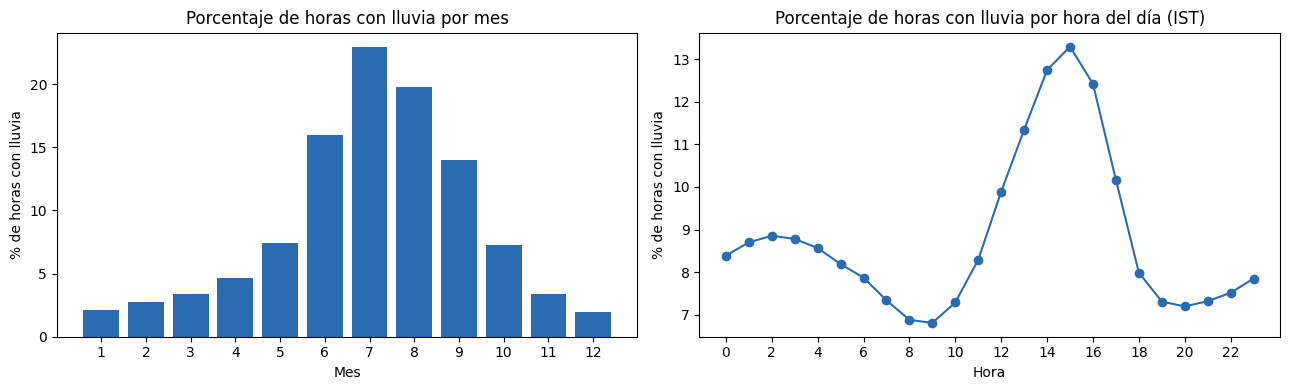

In [ ]:
import matplotlib.pyplot as plt

por_mes  = df.groupBy("mes").agg(F.avg("rain_label").alias("prob_lluvia")).orderBy("mes").toPandas()
por_hora = df.groupBy("hora").agg(F.avg("rain_label").alias("prob_lluvia")).orderBy("hora").toPandas()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(por_mes["mes"], 100 * por_mes["prob_lluvia"], color="#2b6cb0")
ax[0].set(title="Porcentaje de horas con lluvia por mes", xlabel="Mes", ylabel="% de horas con lluvia")
ax[0].set_xticks(range(1, 13))
ax[1].plot(por_hora["hora"], 100 * por_hora["prob_lluvia"], marker="o", color="#2b6cb0")
ax[1].set(title="Porcentaje de horas con lluvia por hora del día (IST)", xlabel="Hora", ylabel="% de horas con lluvia")
ax[1].set_xticks(range(0, 24, 2))
plt.tight_layout(); plt.show()

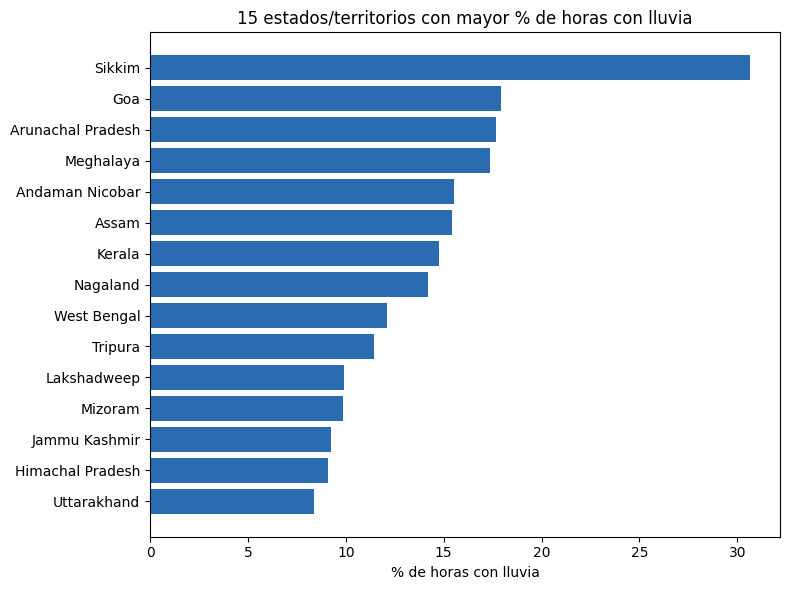

,state,prob_lluvia,mm_anuales_por_ciudad,ciudades
0,Sikkim,0.31,"5,254.25",3
1,Goa,0.18,"2,936.93",3
2,Arunachal Pradesh,0.18,"3,070.74",3
3,Meghalaya,0.17,"3,172.87",4
4,Andaman Nicobar,0.16,"2,227.84",2
5,Assam,0.15,"2,752.88",6
6,Kerala,0.15,"2,401.03",8
7,Nagaland,0.14,"2,606.70",3
8,West Bengal,0.12,"2,277.52",8
9,Tripura,0.11,"2,099.20",3


In [ ]:
por_estado = (df.groupBy("state")
                .agg(F.avg("rain_label").alias("prob_lluvia"),
                     (F.avg("precip_mm") * 24 * 365.25).alias("mm_anuales_por_ciudad"),   # promedio horario x horas en un año
                     F.countDistinct("city").alias("ciudades"))
                .orderBy(F.desc("prob_lluvia")).toPandas())

top = por_estado.head(15).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top["state"], 100 * top["prob_lluvia"], color="#2b6cb0")
plt.title("15 estados/territorios con mayor % de horas con lluvia")
plt.xlabel("% de horas con lluvia"); plt.tight_layout(); plt.show()
por_estado.head(10)

### 5.4 Variables que ditinguen las horas con lluvia

Se compara el promedio de cada variable entre horas con y sin lluvia. Para que las diferencias sean comparables entre variables con unidades distintas, también se expresan en desviaciones estándar. Las variables con mayor diferencia en valor absoluto seríanl as candidatas a ser buenos predictores.

In [ ]:
variables_comp = [c for c in COLS_NUMERICAS if c not in ("precip_mm", "wind_direction_deg")]

comparacion = (df.groupBy("rain_label")
                 .agg(*[F.avg(c).alias(c) for c in variables_comp])
                 .toPandas().set_index("rain_label").sort_index().T)   # sort_index: fila 0 primero, luego 1
comparacion.columns = ["sin lluvia (0)", "con lluvia (1)"]
comparacion["diferencia"] = comparacion["con lluvia (1)"] - comparacion["sin lluvia (0)"]

desv = df.agg(*[F.stddev(c).alias(c) for c in variables_comp]).toPandas().T[0]
comparacion["diferencia (desv. est.)"] = comparacion["diferencia"] / desv.replace(0, float("nan"))
comparacion.sort_values("diferencia (desv. est.)", key=abs, ascending=False)

,sin lluvia (0),con lluvia (1),diferencia,diferencia (desv. est.)
cloud_cover_pct,43.92,92.44,48.52,1.17
humidity_pct,66.73,88.41,21.68,0.96
dew_point_C,15.85,21.02,5.17,0.68
lon,80.74,82.99,2.24,0.34
et0_mm,0.18,0.11,-0.07,-0.33
wind_dir_cos,0.05,-0.16,-0.21,-0.32
solar_radiation_Wm2,213.96,143.88,-70.07,-0.25
pressure_hPa,960.82,947.63,-13.19,-0.22
wind_speed_ms,8.27,9.11,0.83,0.16
wind_dir_sin,-0.08,-0.13,-0.05,-0.07


## 6. Preparación de variables

### 6.1 Decisiones de variables

- Se excluye `precip_mm` de las variables de entrada. `rain_label` se calcula directamente a partir de `precip_mm` (>= 0.5 mm), así que incluirla sería data leakage pues el modelo vería la respuesta y obtendría una precisión artificial alta.
- Se excluyen `state`, `city` y `crops`. Son texto con muchas categorías y la ubicación ya está representada numéricamente por `lat` / `lon`.
- Se excluyen las variables sin información detectadas en la sección 5.1.
- Se incluye `pressure_trend`. El cambio de presión respecto a la hora anterior es información del pasado, no de la respuesta, y una presión que baja suele anticipar mal tiempo.
- `wind_direction_deg` se sustituye por `wind_dir_sin` y `wind_dir_cos`. La dirección es cíclica y el seno-coseno lo representa correctamente.
- Codificación cíclica del tiempo. Como hora del día y el día del año también son cíclicos , se transforman con seno y coseno.
- Variable derivada `dif_temp_rocio` = temperatura − punto de rocío, pues cuando la diferencia es pequeña, el aire está cerca de la saturación y la probabilidad de lluvia aumenta.
- No hay valores nulos así que no se elimina ningún registro. Por seguridad el VectorAssembler descarta cualquier registro inválido que pudiera llegar en datos nuevos.

### 6.2 Transformaciones dentro del pipeline

Las variables derivadas se calculan con un SQLTransformer que forma parte del pipeline de `pyspark.ml`. Así el modelo guardado incluye todas las transformaciones y puede recibir datos crudos para hacer predicciones nuevas sin repetir manualmente el preprocesamiento.

In [ ]:
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import SQLTransformer, VectorAssembler

ETIQUETA = "rain_label"

# Variables meteorológicas crudas
VARS_METEO = [c for c in ["temperature_C", "humidity_pct", "pressure_hPa", "pressure_trend", "dew_point_C",
                          "solar_radiation_Wm2", "cloud_cover_pct", "wind_speed_ms",
                          "wind_dir_sin", "wind_dir_cos", "cape", "et0_mm"]
              if c not in VARS_SIN_INFO]
COLS_ENTRADA = ["fecha_hora", "lat", "lon"] + VARS_METEO

# Variables derivadas que calcula el SQLTransformer
transformador = SQLTransformer(statement='''
    SELECT *,
           sin(2 * pi() * hour(fecha_hora) / 24)          AS hora_sin,
           cos(2 * pi() * hour(fecha_hora) / 24)          AS hora_cos,
           sin(2 * pi() * dayofyear(fecha_hora) / 365.25) AS dia_sin,
           cos(2 * pi() * dayofyear(fecha_hora) / 365.25) AS dia_cos,
           temperature_C - dew_point_C                    AS dif_temp_rocio
    FROM __THIS__''')

VARIABLES = ["lat", "lon"] + VARS_METEO + ["hora_sin", "hora_cos", "dia_sin", "dia_cos", "dif_temp_rocio"]

ensamblador = VectorAssembler(inputCols=VARIABLES, outputCol="features", handleInvalid="skip")

print(f"{len(VARIABLES)} variables de entrada al modelo:")
for v in VARIABLES:
    print("  -", v)
print("\nExcluidas a propósito: precip_mm (fuga de información), state, city, crops, wind_direction_deg",
      *VARS_SIN_INFO, sep=", ")

18 variables de entrada al modelo:
  - lat
  - lon
  - temperature_C
  - humidity_pct
  - pressure_hPa
  - pressure_trend
  - dew_point_C
  - solar_radiation_Wm2
  - cloud_cover_pct
  - wind_speed_ms
  - wind_dir_sin
  - wind_dir_cos
  - et0_mm
  - hora_sin
  - hora_cos
  - dia_sin
  - dia_cos
  - dif_temp_rocio

Excluidas a propósito: precip_mm (fuga de información), state, city, crops, wind_direction_deg, cape


In [ ]:
# Solo las columnas necesarias para el modelo (más anio/state/city para el split y el análisis por estado)
df_modelo = (df.select(COLS_ENTRADA + [ETIQUETA, "anio", "state", "city"])
               .withColumn("label", F.col(ETIQUETA).cast("double")))

## 7. Split validation temporal

Se divide el conjunto en tres partes por año:

| Conjunto | Años | Uso |
|---|---|---|
| Entrenamiento | 1996 - 2019 | Ajustar los modelos y sus hiperparámetros con `TrainValidationSplit` |
| Validación | 2020 - 2022 | Comparar modelos para elegir el mejor, y su umbral de decisión |
| Prueba | 2023 - mar 2026 | Evaluación final con datos que el modelo nunca vio |

En datos horarios dos horas consecutivas de la misma ciudad son muy similares. Con un split aleatorio, el modelo vería en entrenamiento las 14h y en prueba las 15h del mismo día, lo que infla artificialmente las métricas. Separar por años simula el uso real, entrenando con el pasado y prediciendo el futuro.

### 7.1 Muestreo del conjunto de entrenamiento

El entrenamiento tiene alrederor de 36.6 millones de registros y en Colab gratuito entrenar con todos tardaría muchísimo, así que se usa la muestra aleatoria `FRACCION_ENTRENAMIENTO`. Un par de millones de registros es suficiente para que los modelos aprendan los patrones, y la evaluación de prueba se hace sobre todos los registros de 2023 - 2026 (casi 4.9 millones). En un clúster con más recursos bastaría con subir la fracción a 1.

In [ ]:
FRACCION_ENTRENAMIENTO = 0.08   # ~2.9 millones de registros (subir si se cuenta con más recursos)
FRACCION_VALIDACION    = 0.30   # muestra para comparar modelos rápidamente

train_completo = df_modelo.filter(F.col("anio") <= 2019)
val_completo   = df_modelo.filter(F.col("anio").between(2020, 2022))
test           = df_modelo.filter(F.col("anio") >= 2023)

train = train_completo.sample(fraction=FRACCION_ENTRENAMIENTO, seed=SEMILLA)
val   = val_completo.sample(fraction=FRACCION_VALIDACION, seed=SEMILLA)

# Pesos de clase. la clase minoritaria pesa más para que el modelo no la ignore
conteos = dict(train.groupBy("label").count().collect())
n_train = sum(conteos.values())
peso = {k: n_train / (2.0 * v) for k, v in conteos.items()}
train = train.withColumn("peso", F.when(F.col("label") == 1.0, peso[1.0]).otherwise(peso[0.0]))
print("Pesos de clase:", {int(k): round(v, 3) for k, v in peso.items()})

t0 = time.time()
train = train.cache(); n_tr = train.count()
val   = val.cache();   n_va = val.count()
tiempos["Split y caché de entrenamiento/validación"] = time.time() - t0

resumen_split = pd.DataFrame({
    "conjunto": ["Entrenamiento (muestra)", "Validación (muestra)", "Prueba (completo)"],
    "años": ["1996–2019", "2020–2022", "2023–2026"],
    "registros": [n_tr, n_va, test.count()],
    "% lluvia": [100 * train.agg(F.avg("label")).first()[0],
                 100 * val.agg(F.avg("label")).first()[0],
                 100 * test.agg(F.avg("label")).first()[0]]})
resumen_split

Pesos de clase: {1: 5.504, 0: 0.55}


,conjunto,años,registros,% lluvia
0,Entrenamiento (muestra),1996–2019,2928570,9.08
1,Validación (muestra),2020–2022,1373768,8.50
2,Prueba (completo),2023–2026,4898448,7.06


## 8. Generación de modelos con MLlib

Se entrenan dos clasificadores de `pyspark.ml.classification` y se comparan:

### 8.1 Modelo A: Regresión logística con `TrainValidationSplit`

La regresión logística es un modelo lineal y rápido que sirve como baseline. Sus hiperparámetros se eligen con `TrainValidationSplit`, la herramienta de split validation de MLlib, que separa internamente el entrenamiento en 80% / 20%, entrena una vez por cada combinación de la malla de hiperparámetros, se queda con la que obtiene el mejor AUC en el 20% reservado y reentrena con el 100% de los datos.

Malla de búsqueda:
- `regParam`,fuerza de la regularización: 0.0001, 0.001, 0.01
- `elasticNetParam` (0 = L2/Ridge, 1 = L1/Lasso): 0.0, 0.5

> La regresión logística de Spark estandariza internamente las variables (`standardization=True`), por lo que no hace falta un `StandardScaler`.

In [ ]:
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.tuning import ParamGridBuilder, TrainValidationSplit
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

eval_auc_roc = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC")
eval_auc_pr  = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderPR")

lr = LogisticRegression(featuresCol="features", labelCol="label", weightCol="peso", maxIter=50)
pipeline_lr = Pipeline(stages=[transformador, ensamblador, lr])

malla = (ParamGridBuilder()
         .addGrid(lr.regParam, [0.0001, 0.001, 0.01])
         .addGrid(lr.elasticNetParam, [0.0, 0.5])
         .build())

tvs = TrainValidationSplit(estimator=pipeline_lr, estimatorParamMaps=malla, evaluator=eval_auc_roc,
                           trainRatio=0.8, parallelism=2, seed=SEMILLA)

t0 = time.time()
tvs_modelo = tvs.fit(train)
tiempos["Entrenamiento regresión logística (TVS, 6 combinaciones)"] = time.time() - t0
modelo_lr = tvs_modelo.bestModel

print(f"Tiempo de entrenamiento: {tiempos['Entrenamiento regresión logística (TVS, 6 combinaciones)'] / 60:.1f} min\n")
print("AUC-ROC en el 20 % interno de cada combinación:")
for params, metrica in zip(malla, tvs_modelo.validationMetrics):
    print(f"  regParam={params[lr.regParam]:<7} elasticNet={params[lr.elasticNetParam]:<4} ->  AUC-ROC = {metrica:.4f}")
mejor_lr = modelo_lr.stages[-1]
print(f"\nMejores hiperparámetros: regParam={mejor_lr.getRegParam()}, elasticNetParam={mejor_lr.getElasticNetParam()}")

Tiempo de entrenamiento: 9.1 min

AUC-ROC en el 20 % interno de cada combinación:
  regParam=0.0001  elasticNet=0.0  ->  AUC-ROC = 0.9074
  regParam=0.0001  elasticNet=0.5  ->  AUC-ROC = 0.9072
  regParam=0.001   elasticNet=0.0  ->  AUC-ROC = 0.9065
  regParam=0.001   elasticNet=0.5  ->  AUC-ROC = 0.9065
  regParam=0.01    elasticNet=0.0  ->  AUC-ROC = 0.9042
  regParam=0.01    elasticNet=0.5  ->  AUC-ROC = 0.9049

Mejores hiperparámetros: regParam=0.0001, elasticNetParam=0.0


### 8.2 Modelo B - Random Forest

Un Random Forest combina muchos árboles de decisión entrenados sobre submuestras de los datos y de las variables. Logra capturar relaciones no lineales e interacciones que un modelo lineal no puede representar, y es por esto que se eligió entrenar para compararlo con el Modelo A.

Hiperparámetros elegidos:
- `numTrees = 40`
- `maxDepth = 10`: profundidad máxima de cada árbol.
- `featureSubsetStrategy = "sqrt"`: cada división considera sqrt(n de variables) al azar.
- `subsamplingRate = 0.7`: cada árbol se entrena con el 70% de la muestra.

In [ ]:
rf = RandomForestClassifier(featuresCol="features", labelCol="label", weightCol="peso",
                            numTrees=40, maxDepth=10, featureSubsetStrategy="sqrt",
                            subsamplingRate=0.7, maxBins=64, seed=SEMILLA)
pipeline_rf = Pipeline(stages=[transformador, ensamblador, rf])

t0 = time.time()
modelo_rf = pipeline_rf.fit(train)
tiempos["Entrenamiento Random Forest"] = time.time() - t0
print(f"Tiempo de entrenamiento: {tiempos['Entrenamiento Random Forest'] / 60:.1f} min")

Tiempo de entrenamiento: 9.4 min


## 9. Evaluación y selección del modelo

Se usan los evaluadores de `pyspark.ml.evaluation`:

| Métrica | Evaluador | Qué mide |
|---|---|---|
| AUC-ROC | `BinaryClassificationEvaluator` | Capacidad de ordenar correctamente horas con lluvia sobre horas sin lluvia (1 = perfecto, 0.5 = azar). |
| AUC-PR | `BinaryClassificationEvaluator` | Área bajo la curva precisión-recall, más exigente y más informativa cuando la clase positiva es minoritaria. |
| Accuracy | `MulticlassClassificationEvaluator` | Porcentaje total de aciertos. |
| Precisión (lluvia) | `MulticlassClassificationEvaluator` | De las horas que el modelo predijo con lluvia, cuántas realmente tuvieron lluvia. |
| Recall (lluvia) | `MulticlassClassificationEvaluator` | De las horas que realmente tuvieron lluvia, cuántas detectó el modelo. |
| F1 (lluvia) | `MulticlassClassificationEvaluator` | Media armónica de precisión y recall de la clase lluvia. |

Criterio de selección: el modelo con mayor AUC-PR en validación, pues es la métrica más sensible al desempeño sobre la clase minoritaria.

In [ ]:
from pyspark.ml.functions import vector_to_array

def predecir(modelo, datos, umbral=0.5):
    # Aplica el pipeline y decide 'lluvia' cuando la probabilidad de lluvia >= umbral
    return (modelo.transform(datos)
                  .withColumn("prob_lluvia", vector_to_array("probability")[1])
                  .withColumn("prediction", (F.col("prob_lluvia") >= umbral).cast("double")))

def evaluar(pred, nombre):
    pred = pred.select("label", "prediction", "rawPrediction", "prob_lluvia").cache()
    m = {"modelo": nombre,
         "AUC-ROC": eval_auc_roc.evaluate(pred),
         "AUC-PR":  eval_auc_pr.evaluate(pred)}
    for etiqueta, metrica, extra in [("Accuracy", "accuracy", {}),
                                     ("Precisión (lluvia)", "precisionByLabel", {"metricLabel": 1.0}),
                                     ("Recall (lluvia)", "recallByLabel", {"metricLabel": 1.0}),
                                     ("F1 (lluvia)", "fMeasureByLabel", {"metricLabel": 1.0}),
                                     ("F1 ponderado", "f1", {})]:
        ev = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction",
                                               metricName=metrica, **extra)
        m[etiqueta] = ev.evaluate(pred)
    pred.unpersist()
    return m

t0 = time.time()
pred_val_lr = predecir(modelo_lr, val)
pred_val_rf = predecir(modelo_rf, val)
resultados_val = pd.DataFrame([evaluar(pred_val_lr, "Regresión logística"),
                               evaluar(pred_val_rf, "Random Forest")]).set_index("modelo")
tiempos["Evaluación en validación"] = time.time() - t0
resultados_val

,AUC-ROC,AUC-PR,Accuracy,Precisión (lluvia),Recall (lluvia),F1 (lluvia),F1 ponderado
modelo,,,,,,,
Regresión logística,0.90,0.45,0.77,0.26,0.91,0.40,0.82
Random Forest,0.93,0.55,0.80,0.29,0.92,0.44,0.84


In [ ]:
nombre_mejor = resultados_val["AUC-PR"].idxmax()
modelo_final = modelo_lr if nombre_mejor == "Regresión logística" else modelo_rf
pred_val_mejor = pred_val_lr if nombre_mejor == "Regresión logística" else pred_val_rf
print("Modelo seleccionado:", nombre_mejor)

Modelo seleccionado: Random Forest


### 9.1 Ajuste del umbral de decisión

Por defecto un clasificador predice "lluvia" cuando la probabilidad es >= 0.5, pero como se entrenó con pesos de clase, ese umbral puede no ser el que equilibra mejor precisión y recall. Con el conjunto de validación se prueban varios umbrales y se elige el que maximiza el F1 de la clase lluvia. Este umbral se fija antes de usar el conjunto de prueba.

Todas las combinaciones se calculan en una sola pasada sobre los datos con agregaciones condicionales.

Umbral elegido (máximo F1 en validación): 0.8


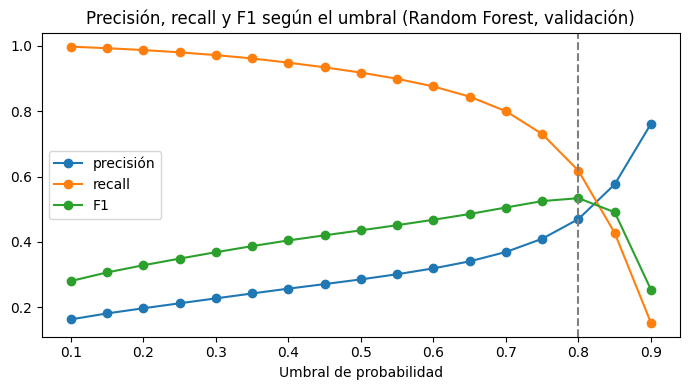

,umbral,precisión,recall,F1
0,0.10,0.16,1.00,0.28
1,0.15,0.18,0.99,0.31
2,0.20,0.20,0.99,0.33
3,0.25,0.21,0.98,0.35
4,0.30,0.23,0.97,0.37
5,0.35,0.24,0.96,0.39
6,0.40,0.26,0.95,0.40
7,0.45,0.27,0.93,0.42
8,0.50,0.29,0.92,0.44
9,0.55,0.30,0.90,0.45


In [ ]:
umbrales = [round(0.10 + 0.05 * i, 2) for i in range(17)]
p = pred_val_mejor.select("label", "prob_lluvia")
aggs = []
for u in umbrales:
    pos = F.col("prob_lluvia") >= u
    aggs += [F.sum((pos & (F.col("label") == 1)).cast("int")).alias(f"vp_{int(u*100)}"),
             F.sum((pos & (F.col("label") == 0)).cast("int")).alias(f"fp_{int(u*100)}"),
             F.sum((~pos & (F.col("label") == 1)).cast("int")).alias(f"fn_{int(u*100)}")]
fila = p.agg(*aggs).first()

filas = []
for u in umbrales:
    k = int(u * 100)
    vp, fp, fn = fila[f"vp_{k}"], fila[f"fp_{k}"], fila[f"fn_{k}"]
    prec = vp / (vp + fp) if vp + fp else 0.0
    rec  = vp / (vp + fn) if vp + fn else 0.0
    f1   = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    filas.append({"umbral": u, "precisión": prec, "recall": rec, "F1": f1})
tabla_umbral = pd.DataFrame(filas)

UMBRAL = float(tabla_umbral.loc[tabla_umbral["F1"].idxmax(), "umbral"])
print(f"Umbral elegido (máximo F1 en validación): {UMBRAL}")

plt.figure(figsize=(7, 4))
for col in ["precisión", "recall", "F1"]:
    plt.plot(tabla_umbral["umbral"], tabla_umbral[col], marker="o", label=col)
plt.axvline(UMBRAL, ls="--", color="gray")
plt.title(f"Precisión, recall y F1 según el umbral ({nombre_mejor}, validación)")
plt.xlabel("Umbral de probabilidad"); plt.legend(); plt.tight_layout(); plt.show()
tabla_umbral

In [ ]:
train.unpersist(); val.unpersist()   # liberar memoria antes de la evaluación final

DataFrame[fecha_hora: timestamp, lat: double, lon: double, temperature_C: double, humidity_pct: double, pressure_hPa: double, pressure_trend: double, dew_point_C: double, solar_radiation_Wm2: double, cloud_cover_pct: double, wind_speed_ms: double, wind_dir_sin: double, wind_dir_cos: double, et0_mm: double, rain_label: int, anio: int, state: string, city: string, label: double]

## 10. Evaluación final en el conjunto de prueba

El modelo seleccionado, con el umbral elegido en validación, se evalúa una sola vez sobre todos los registros de 2023 a 2026, es decir el conjunto de prueba. Este resultado es la estimación real de cómo se comportaría el modelo con datos futuros, pues el conjunto de prueba son datos que no habían sido vistos nunca por el modelo.

Como referencia se incluye un modelo ingenuo que siempre predice no llueve, y si el modelo seleccionado no lo supera claramente en F1 y AUC, no aporta valor.

In [ ]:
t0 = time.time()
pred_test = predecir(modelo_final, test, UMBRAL).cache()
metricas_test = evaluar(pred_test, f"{nombre_mejor} (umbral {UMBRAL})")
tiempos["Evaluación en prueba (conjunto completo)"] = time.time() - t0

tasa_test = pred_test.agg(F.avg("label")).first()[0]
ingenuo = {"modelo": "Ingenuo: siempre 'no llueve'", "AUC-ROC": 0.5, "AUC-PR": tasa_test,
           "Accuracy": 1 - tasa_test, "Precisión (lluvia)": 0.0, "Recall (lluvia)": 0.0,
           "F1 (lluvia)": 0.0, "F1 ponderado": None}
resultados_test = pd.DataFrame([metricas_test, ingenuo]).set_index("modelo")
print(f"Registros evaluados: {pred_test.count():,}")
resultados_test

Registros evaluados: 4,898,448


,AUC-ROC,AUC-PR,Accuracy,Precisión (lluvia),Recall (lluvia),F1 (lluvia),F1 ponderado
modelo,,,,,,,
Random Forest (umbral 0.8),0.93,0.52,0.91,0.41,0.65,0.50,0.92
Ingenuo: siempre 'no llueve',0.50,0.07,0.93,0.00,0.00,0.00,NaN


### 10.1 Matriz de confusión

- Verdaderos positivos (VP): llovió y el modelo lo predijo.
- Falsos positivos (FP): el modelo predijo lluvia, pero no llovió.
- Falsos negativos (FN): llovió y el modelo no lo detectó.
- Verdaderos negativos (VN): no llovió y el modelo lo predijo correctamente.

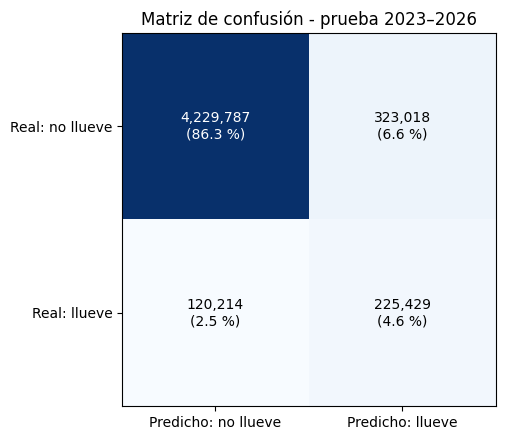

,Predicho: no llueve,Predicho: llueve
Real: no llueve,4229787,323018
Real: llueve,120214,225429


In [ ]:
mc = (pred_test.groupBy("label", "prediction").count().toPandas()
        .pivot(index="label", columns="prediction", values="count").fillna(0).astype(int))
mc.index = ["Real: no llueve", "Real: llueve"]
mc.columns = ["Predicho: no llueve", "Predicho: llueve"]

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(mc.values, cmap="Blues")
for i in range(2):
    for j in range(2):
        v = mc.values[i, j]
        ax.text(j, i, f"{v:,}\n({100 * v / mc.values.sum():.1f} %)", ha="center", va="center",
                color="white" if v > mc.values.max() / 2 else "black")
ax.set_xticks([0, 1]); ax.set_xticklabels(mc.columns)
ax.set_yticks([0, 1]); ax.set_yticklabels(mc.index)
ax.set_title("Matriz de confusión - prueba 2023–2026")
plt.tight_layout(); plt.show()
mc

### 10.2 Importancia de las variables

Muestra qué variables pesan más en las decisiones del modelo. En el Random Forest es la reducción promedio de impureza que aporta cada variable, y en la regresión logística es la magnitud del coeficiente.

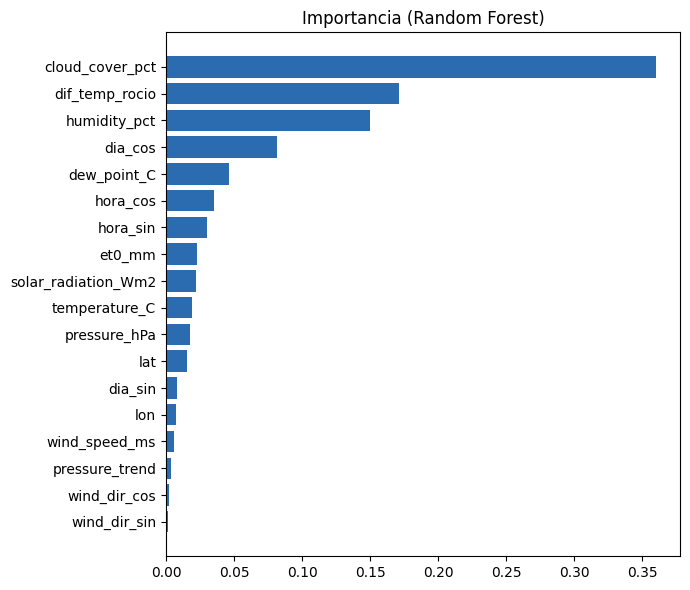

,variable,importancia
0,cloud_cover_pct,0.36
1,dif_temp_rocio,0.17
2,humidity_pct,0.15
3,dia_cos,0.08
4,dew_point_C,0.05
5,hora_cos,0.04
6,hora_sin,0.03
7,et0_mm,0.02
8,solar_radiation_Wm2,0.02
9,temperature_C,0.02


In [ ]:
clasificador = modelo_final.stages[-1]
if hasattr(clasificador, "featureImportances"):
    valores, titulo = clasificador.featureImportances.toArray(), "Importancia (Random Forest)"
else:
    # coeficiente x desviación estándar ~ efecto por desviación estándar de la variable
    desv = (train_completo.sample(fraction=0.01, seed=SEMILLA)
            .transform(lambda d: modelo_final.stages[0].transform(d))
            .select([F.stddev(v).alias(v) for v in VARIABLES]).first())
    valores = [abs(c) * (desv[v] or 0) for c, v in zip(clasificador.coefficients.toArray(), VARIABLES)]
    titulo = "|Coeficiente| x desviación estándar (regresión logística)"

importancias = pd.DataFrame({"variable": VARIABLES, "importancia": valores}).sort_values("importancia")
plt.figure(figsize=(7, 6))
plt.barh(importancias["variable"], importancias["importancia"], color="#2b6cb0")
plt.title(titulo); plt.tight_layout(); plt.show()
importancias.sort_values("importancia", ascending=False).reset_index(drop=True)

### 10.3 Desempeño por estado

Permite ver si el modelo funciona igual de bien en todo el país o si hay regiones donde falla más.

In [ ]:
por_estado_test = (pred_test.groupBy("state").agg(
        F.count("*").alias("registros"),
        F.avg("label").alias("tasa_real"),
        F.avg("prediction").alias("tasa_predicha"),
        F.sum(((F.col("prediction") == 1) & (F.col("label") == 1)).cast("int")).alias("vp"),
        F.sum(((F.col("prediction") == 1) & (F.col("label") == 0)).cast("int")).alias("fp"),
        F.sum(((F.col("prediction") == 0) & (F.col("label") == 1)).cast("int")).alias("fn"))
    .withColumn("precision", F.col("vp") / (F.col("vp") + F.col("fp")))
    .withColumn("recall",    F.col("vp") / (F.col("vp") + F.col("fn")))
    .withColumn("f1", 2 * F.col("precision") * F.col("recall") / (F.col("precision") + F.col("recall")))
    .orderBy(F.desc("f1"))
    .toPandas())
por_estado_test[["state", "registros", "tasa_real", "tasa_predicha", "precision", "recall", "f1"]]

,state,registros,tasa_real,tasa_predicha,precision,recall,f1
0,Daman Diu,28152,0.09,0.12,0.58,0.76,0.66
1,Goa,84456,0.16,0.17,0.61,0.66,0.63
2,Sikkim,84456,0.19,0.29,0.52,0.79,0.63
3,Dadra Nagar Haveli,28152,0.09,0.15,0.47,0.81,0.59
4,Telangana,168912,0.06,0.08,0.50,0.66,0.57
5,Andaman Nicobar,56304,0.12,0.16,0.49,0.67,0.56
6,Assam,168912,0.12,0.17,0.46,0.69,0.56
7,Maharashtra,253368,0.07,0.11,0.46,0.69,0.56
8,Gujarat,197064,0.05,0.08,0.43,0.72,0.54
9,Chhattisgarh,140760,0.07,0.12,0.42,0.71,0.53


## 11. Predicciones con datos nuevos

### 11.1 Guardar y volver a cargar el modelo

El pipeline completo (transformaciones + ensamblador + clasificador) se guarda en disco junto con el umbral elegido. Después se vuelve a cargar con `PipelineModel.load`, como se haría en una app que use el modelo en producción.

In [ ]:
modelo_final.write().overwrite().save(RUTA_MODELO)
with open(os.path.join(DIR_TRABAJO, "umbral.json"), "w") as f:
    json.dump({"modelo": nombre_mejor, "umbral": UMBRAL, "variables": VARIABLES}, f, ensure_ascii=False)

modelo_cargado = PipelineModel.load(RUTA_MODELO)
with open(os.path.join(DIR_TRABAJO, "umbral.json")) as f:
    UMBRAL_CARGADO = json.load(f)["umbral"]
print("Modelo cargado desde:", RUTA_MODELO)
print("Etapas del pipeline:", [type(s).__name__ for s in modelo_cargado.stages])

Modelo cargado desde: /content/portafolio_m6/modelo_lluvia
Etapas del pipeline: ['SQLTransformer', 'VectorAssembler', 'RandomForestClassificationModel']


### 11.2 Predicciones sobre registros reales del periodo de prueba

Se toman horas concretas de algunas ciudades en 2024 (temporada de monzón y temporada seca) y se comparan la probabilidad estimada, la predicción y lo que realmente ocurrió.

In [ ]:
ciudades = ["Mumbai", "Delhi", "New Delhi", "Chennai", "Kolkata", "Bengaluru", "Bangalore", "Jaipur"]
fechas = ["2024-07-15 15:00:00", "2024-01-15 12:00:00", "2024-11-20 06:00:00"]

muestra_real = (test.filter(F.lower("city").isin([c.lower() for c in ciudades]) &
                            F.col("fecha_hora").isin([F.lit(f).cast("timestamp") for f in fechas])))
if muestra_real.count() == 0:   # si nombres o fechas no coinciden se us auna muestra aleatoria
    muestra_real = test.sample(fraction=0.0001, seed=SEMILLA).limit(15)

(predecir(modelo_cargado, muestra_real, UMBRAL_CARGADO)
   .select("city", "state", "fecha_hora", "humidity_pct", "cloud_cover_pct",
           F.round("prob_lluvia", 3).alias("prob_lluvia"),
           F.col("prediction").cast("int").alias("predicción"),
           F.col("label").cast("int").alias("real"))
   .orderBy("fecha_hora", "city")
   .show(30, truncate=False))

+---------+-----------+-------------------+------------+---------------+-----------+----------+----+
|city     |state      |fecha_hora         |humidity_pct|cloud_cover_pct|prob_lluvia|predicción|real|
+---------+-----------+-------------------+------------+---------------+-----------+----------+----+
|Bengaluru|Karnataka  |2024-01-15 12:00:00|41.0        |55.0           |0.056      |0         |0   |
|Chennai  |Tamil Nadu |2024-01-15 12:00:00|62.0        |92.0           |0.098      |0         |0   |
|Jaipur   |Rajasthan  |2024-01-15 12:00:00|53.0        |43.0           |0.066      |0         |0   |
|Kolkata  |West Bengal|2024-01-15 12:00:00|57.0        |2.0            |0.01       |0         |0   |
|Mumbai   |Maharashtra|2024-01-15 12:00:00|26.0        |0.0            |0.004      |0         |0   |
|New Delhi|Delhi      |2024-01-15 12:00:00|70.0        |73.0           |0.511      |0         |0   |
|Bengaluru|Karnataka  |2024-07-15 15:00:00|93.0        |100.0          |0.954      |1      

### 11.3 Predicciones sobre escenarios hipotéticos

Se construyen a mano tres situaciones meteorológicas que no existen en el dataset, con los mismos campos crudos que tendría una nueva observación. El pipeline calcula automáticamente las variables derivadas y devuelve la probabilidad de lluvia.

In [ ]:
import math
from datetime import datetime

def viento(grados):
    return math.sin(math.radians(grados)), math.cos(math.radians(grados))

# Valores en las mismas unidades del dataset
escenarios = [
    # nombre, fecha, lat, lon, temp, humedad, presión, tendencia presión, rocío, radiación, nubes, viento, dir °, et0
    ("Tarde de monzón en Mumbai",        "2026-07-20 16:00:00", 19.08, 72.88, 27.5, 93, 1000.5, -0.6, 26.3, 120, 100, 20.0, 250, 0.08),
    ("Mañana de invierno seco en Delhi", "2026-12-20 10:00:00", 28.61, 77.21, 17.0, 45,  992.0,  0.4,  5.0, 450,   5,  6.0, 300, 0.20),
    ("Tarde pre-monzónica en Kolkata",   "2026-05-25 17:00:00", 22.57, 88.36, 33.0, 72,  998.5, -0.9, 27.3, 250,  65, 12.0, 180, 0.35),
]
filas = []
for nom, fh, la, lo, t, h, p, tend, rocio, rad, nub, vel, dirg, et0 in escenarios:
    s, c = viento(dirg)
    filas.append({"escenario": nom, "fecha_hora": datetime.fromisoformat(fh), "lat": la, "lon": lo,
                  "temperature_C": t, "humidity_pct": float(h), "pressure_hPa": p, "pressure_trend": tend,
                  "dew_point_C": rocio, "solar_radiation_Wm2": float(rad), "cloud_cover_pct": float(nub),
                  "wind_speed_ms": vel, "wind_dir_sin": s, "wind_dir_cos": c, "cape": 0.0, "et0_mm": et0})

df_escenarios = spark.createDataFrame(pd.DataFrame(filas)).select(["escenario"] + COLS_ENTRADA)

(predecir(modelo_cargado, df_escenarios, UMBRAL_CARGADO)
   .select("escenario", F.round("prob_lluvia", 3).alias("prob_lluvia"),
           F.when(F.col("prediction") == 1, "Lluvia").otherwise("Sin lluvia").alias("predicción"))
   .show(truncate=False))

+--------------------------------+-----------+----------+
|escenario                       |prob_lluvia|predicción|
+--------------------------------+-----------+----------+
|Tarde de monzón en Mumbai       |0.924      |Lluvia    |
|Mañana de invierno seco en Delhi|0.004      |Sin lluvia|
|Tarde pre-monzónica en Kolkata  |0.554      |Sin lluvia|
+--------------------------------+-----------+----------+



## 12. Resumen de eficiencia

Decisiones tomadas para procesar ~46 millones de registros en una máquina promedio:

| Decisión | Efecto |
|---|---|
| Esquema explícito al leer el CSV | Evita una pasada completa extra sobre los 7.2GB para inferir tipos. |
| Conversión única a Parquet | Archivo mucho más pequeño y cada consulta lee solo las columnas que necesita. |
| Agregaciones en Spark y `toPandas()` solo de resultados pequeños | La memoria de Python nunca recibe los datos completos. |
| Métricas de varios umbrales en una sola agregación | Una pasada en lugar de una por umbral. |
| `cache()` de los conjuntos que se reutilizan y `unpersist()` al terminar | Evita releer y recalcular, también libera memoria para la siguiente etapa. |
| `spark.sql.shuffle.partitions = 32` | Menos tareas diminutas en una sola máquina. |
| Muestreo para entrenar y evaluación completa en prueba | Entrenamiento en minutos sin sacrificar la validez de la evaluación final. |
| Pipeline con `SQLTransformer` | El preprocesamiento viaja con el modelo y no hay que repetirlo a mano. |

Tiempos medidos en esta ejecución:

In [ ]:
pd.DataFrame({"etapa": list(tiempos.keys()),
              "minutos": [v / 60 for v in tiempos.values()]})

,etapa,minutos
0,Descarga desde Kaggle,1.95
1,Conversión CSV -> Parquet,9.93
2,Conteo de registros (Parquet),0.05
3,Split y caché de entrenamiento/validación,0.74
4,"Entrenamiento regresión logística (TVS, 6 comb...",9.12
5,Entrenamiento Random Forest,9.37
6,Evaluación en validación,2.24
7,Evaluación en prueba (conjunto completo),4.71


## 13. Tablero de visualización en Tableau

### 13.1 Preparación de los datos para Tableau

Tableau Public limita cada fuente de datos a 15 millones de filas, y además no tendría sentido graficar 46 millones de puntos. Por eso Spark resume la base completa en tablas pequeñas que se exportan como CSV:

| Archivo | Nivel de detalle | Filas | Uso en el tablero |
|---|---|---|---|
| `clima_ciudad_mes.csv` | ciudad x año x mes | 63,163 | Mapa, estacionalidad y tendencia histórica |
| `lluvia_estado_mes_hora.csv` | estado x mes x hora | 10,656 | Ciclo diario de la lluvia |
| `predicciones_ciudad_mes.csv` | ciudad x año x mes (prueba 2023-2026) | 6,786 | Desempeño del modelo por región y en el tiempo |
| `importancia_variables.csv` | variable | 18 | Qué variables usa el modelo |

Se exportan los conteos (`horas`, `horas_lluvia`, `vp`, `fp`...) y Tableau calcula `SUM(horas_lluvia) / SUM(horas)` al nivel que se esté viendo (ciudad, estado o país).

In [ ]:
DIR_TABLEAU = os.path.join(DIR_TRABAJO, "tableau")
os.makedirs(DIR_TABLEAU, exist_ok=True)

# Temporadas climáticas de India y conjunto del split
temporada = (F.when(F.col("mes").isin(1, 2), "1. Invierno (ene-feb)")
              .when(F.col("mes").between(3, 5), "2. Pre-monzón (mar-may)")
              .when(F.col("mes").between(6, 9), "3. Monzón (jun-sep)")
              .otherwise("4. Post-monzón (oct-dic)"))
conjunto = (F.when(F.col("anio") <= 2019, "Entrenamiento")
             .when(F.col("anio") <= 2022, "Validación")
             .otherwise("Prueba"))

t0 = time.time()

# clima por ciudad y mes
clima_mensual = (df.groupBy("state", "city", "lat", "lon", "crops", "anio", "mes")
    .agg(F.count("*").alias("horas"),
         F.sum("rain_label").alias("horas_lluvia"),
         F.round(F.sum("precip_mm"), 1).alias("precip_total_mm"),
         F.round(F.max("precip_mm"), 1).alias("precip_max_hora_mm"),
         F.round(F.avg("temperature_C"), 2).alias("temp_media_C"),
         F.round(F.avg("humidity_pct"), 2).alias("humedad_media_pct"),
         F.round(F.avg("cloud_cover_pct"), 2).alias("nubosidad_media_pct"),
         F.round(F.avg("wind_speed_ms"), 2).alias("viento_medio_kmh"))
    .withColumn("fecha", F.make_date("anio", "mes", F.lit(1)))
    .withColumn("temporada", temporada)
    .withColumn("conjunto", conjunto)
    .toPandas())

# ciclo diario de la lluvia (estado x mes x hora)
lluvia_hora = (df.groupBy("state", "mes", "hora")
    .agg(F.count("*").alias("horas"), F.sum("rain_label").alias("horas_lluvia"))
    .withColumn("temporada", temporada)
    .toPandas())

# oredicciones del modelo en el conjunto de prueba por ciudad y mes
llovio, predijo = F.col("label") == 1, F.col("prediction") == 1
pred_mensual = (pred_test.withColumn("mes", F.month("fecha_hora"))
    .groupBy("state", "city", "lat", "lon", "anio", "mes")
    .agg(F.count("*").alias("horas"),
         F.sum(llovio.cast("int")).alias("lluvia_real"),
         F.sum(predijo.cast("int")).alias("lluvia_predicha"),
         F.sum((llovio & predijo).cast("int")).alias("vp"),
         F.sum((~llovio & predijo).cast("int")).alias("fp"),
         F.sum((llovio & ~predijo).cast("int")).alias("fn"),
         F.sum((~llovio & ~predijo).cast("int")).alias("vn"),
         F.round(F.avg("prob_lluvia"), 4).alias("prob_media"))
    .withColumn("fecha", F.make_date("anio", "mes", F.lit(1)))
    .withColumn("temporada", temporada)
    .toPandas())

# importancia de las variables del modelo final
tabla_importancia = importancias.sort_values("importancia", ascending=False)

archivos = {"clima_ciudad_mes.csv": clima_mensual,
            "lluvia_estado_mes_hora.csv": lluvia_hora,
            "predicciones_ciudad_mes.csv": pred_mensual,
            "importancia_variables.csv": tabla_importancia}
for nombre, tabla in archivos.items():
    tabla.to_csv(os.path.join(DIR_TABLEAU, nombre), index=False, encoding="utf-8")
    print(f"{nombre:30s} {len(tabla):>8,} filas")
tiempos["Exportación para Tableau"] = time.time() - t0

# exporta .zip con los 4 archivos
ruta_zip = shutil.make_archive(os.path.join(DIR_TRABAJO, "datos_tableau"), "zip", DIR_TABLEAU)
print("\nArchivo para Tableau:", ruta_zip)
if EN_COLAB:
    from google.colab import files
    files.download(ruta_zip)

clima_ciudad_mes.csv             63,163 filas
lluvia_estado_mes_hora.csv       10,656 filas
predicciones_ciudad_mes.csv       6,786 filas
importancia_variables.csv            18 filas

Archivo para Tableau: /content/portafolio_m6/datos_tableau.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 13.2 Tablero publicado en Tableau Public

**Enlace:** https://public.tableau.com/shared/CSNNYCNG5?:display_count=n&:origin=viz_share_link

El tablero se construyó con los cuatro archivos agregados que Spark generó en la sección anterior a partir de los 46 millones de registros, y tiene dos dashboards: Clima y Modelo. En ambos al hacer clic en una ciudad del mapa se pueden filtrar las demás gráficas.


**Dashboard Clima**
| Visualización | Qué muestra |
|---|---|
| Mapa de lluvia | Precipitación anual y porcentaje de horas con lluvia de las 175 ciudades |
| Estacionalidad | % de horas con lluvia por estado y mes |
| Tendencia histórica | Precipitación media anual 1996-2025 con línea de tendencia |
| Ciclo diario | % de horas con lluvia por mes y hora del día |

Filtros: temporada y estado.

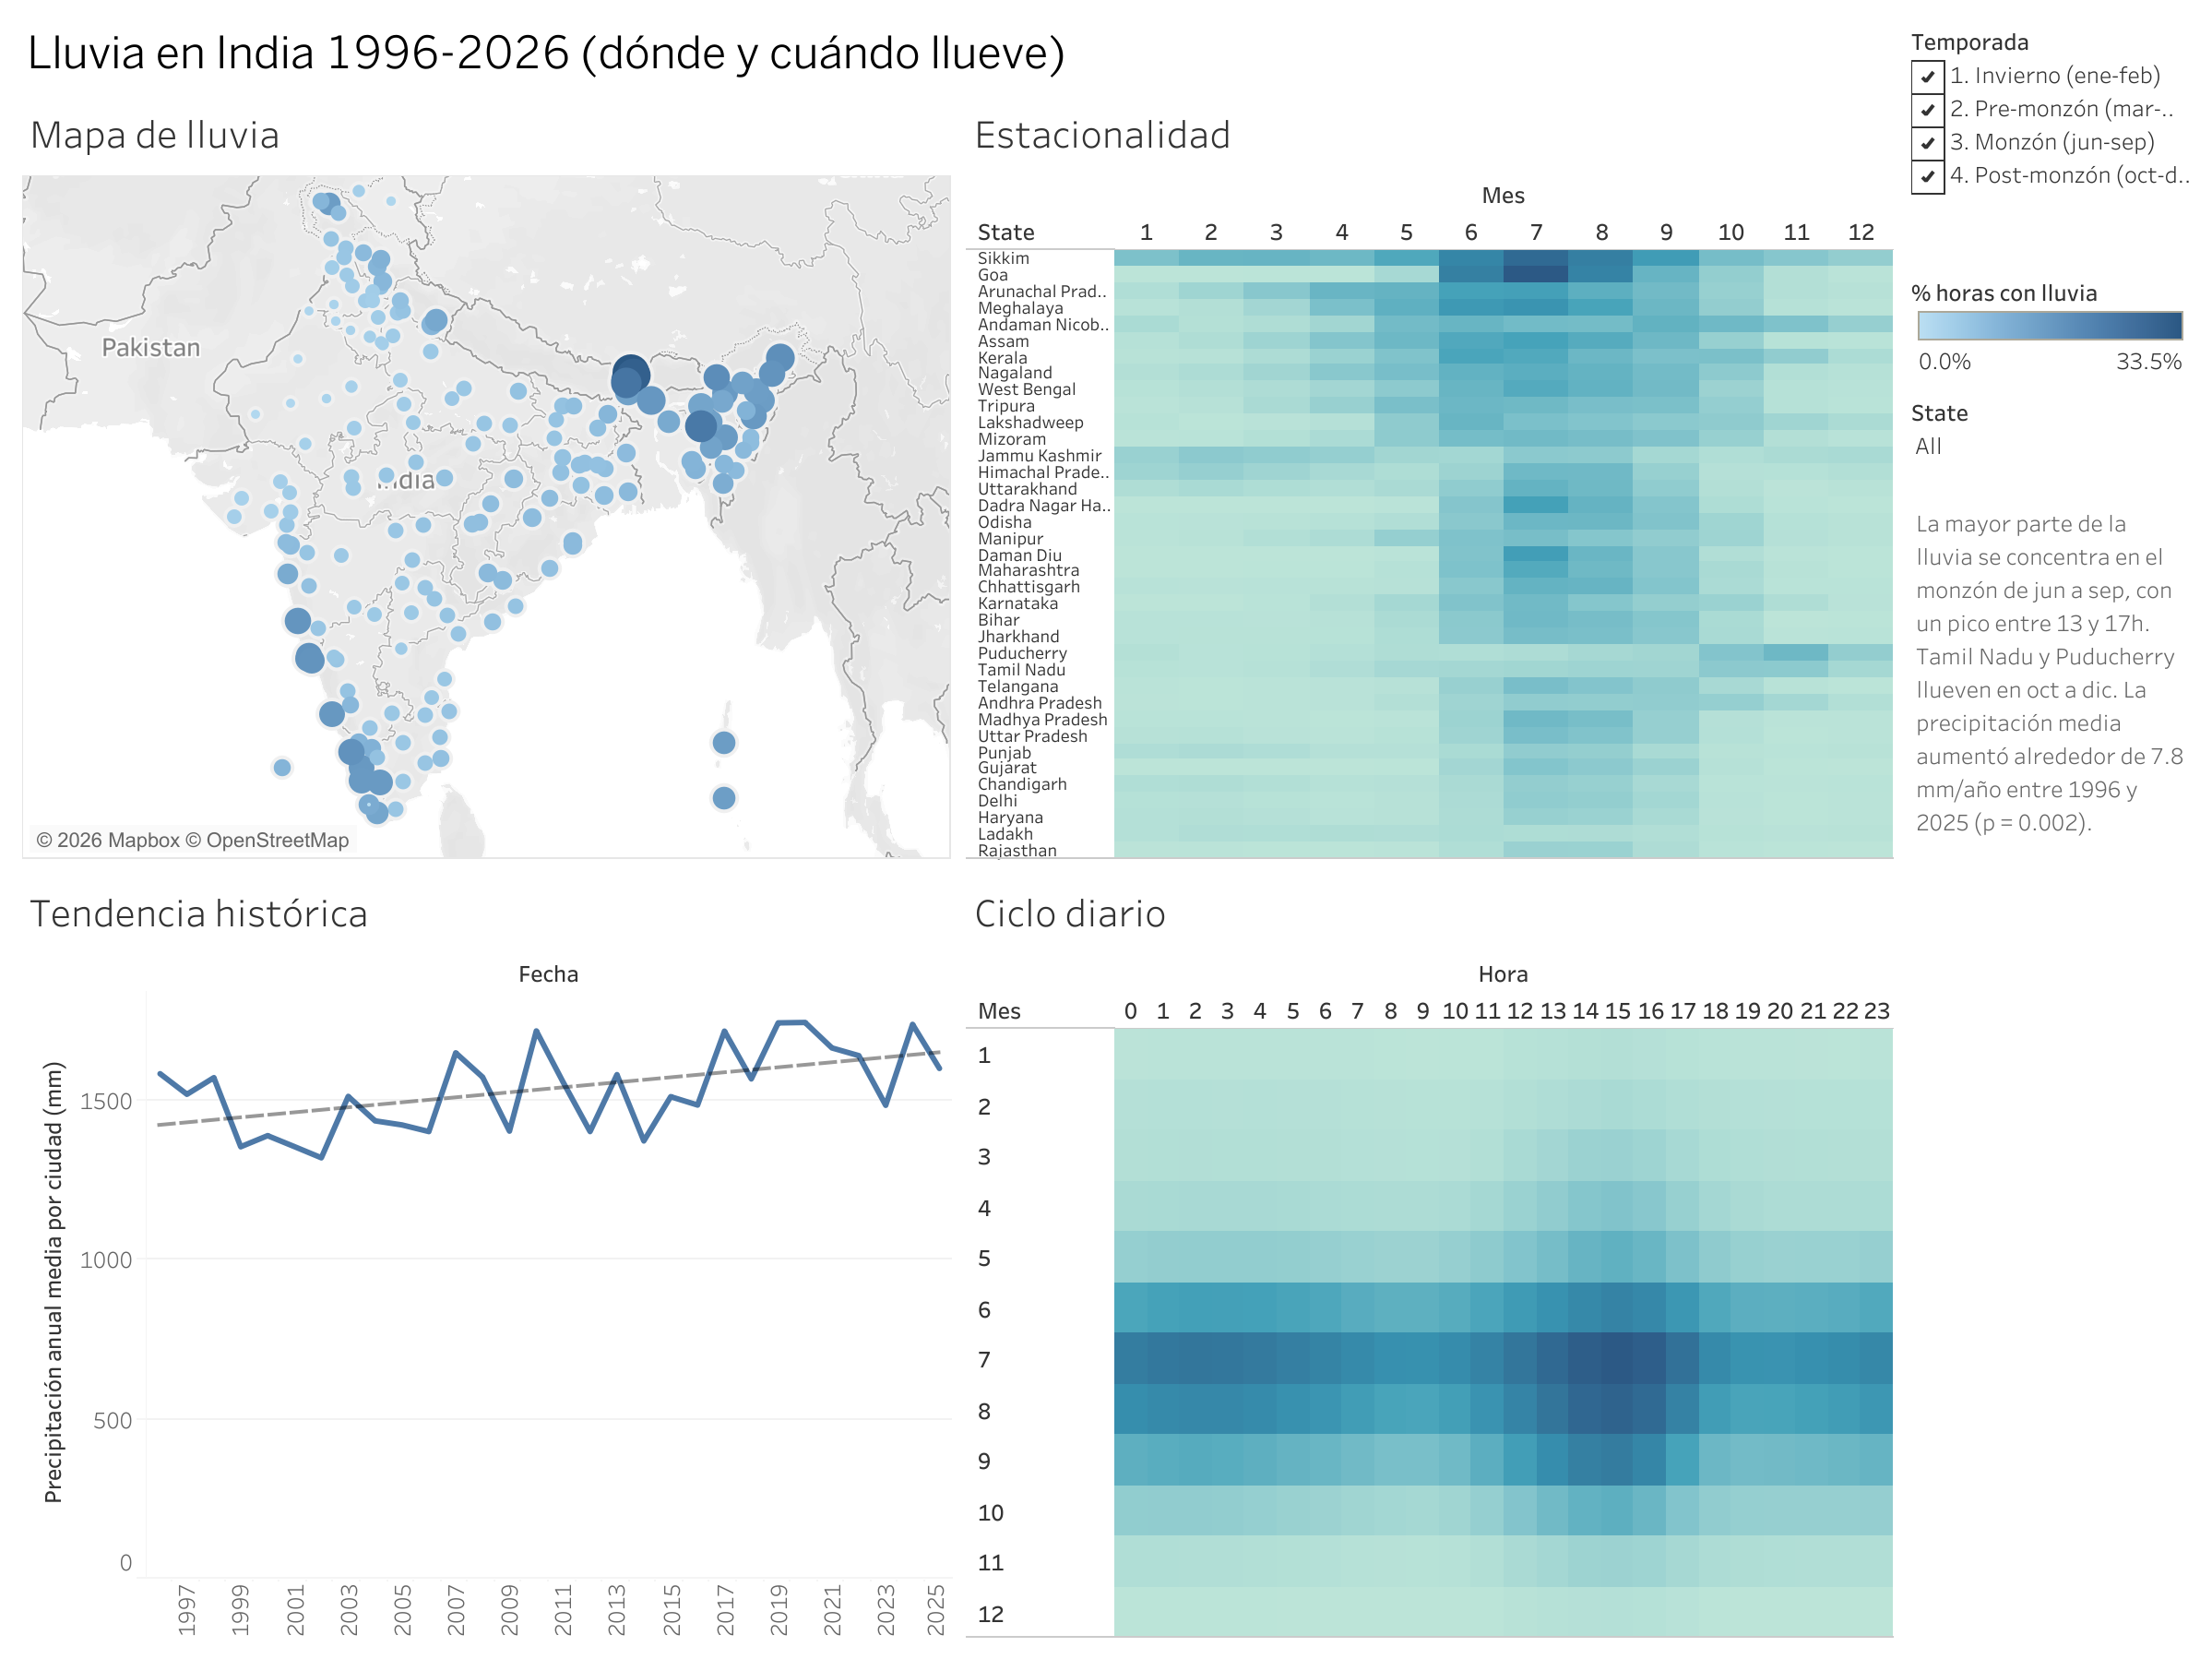

**Dashboard Modelo**

| Visualización | Qué muestra |
|---|---|
| Indicadores | F1 = 0.50, precisión = 0.41 y recall = 0.65 en prueba (2023-2026). Se recalculan para la ciudad seleccionada |
| Confiabilidad por región | F1 de cada ciudad en el periodo de prueba |
| Real vs predicho | Horas con lluvia reales y predichas por mes |
| Importancia de variables | Peso de cada variable en el Random Forest |

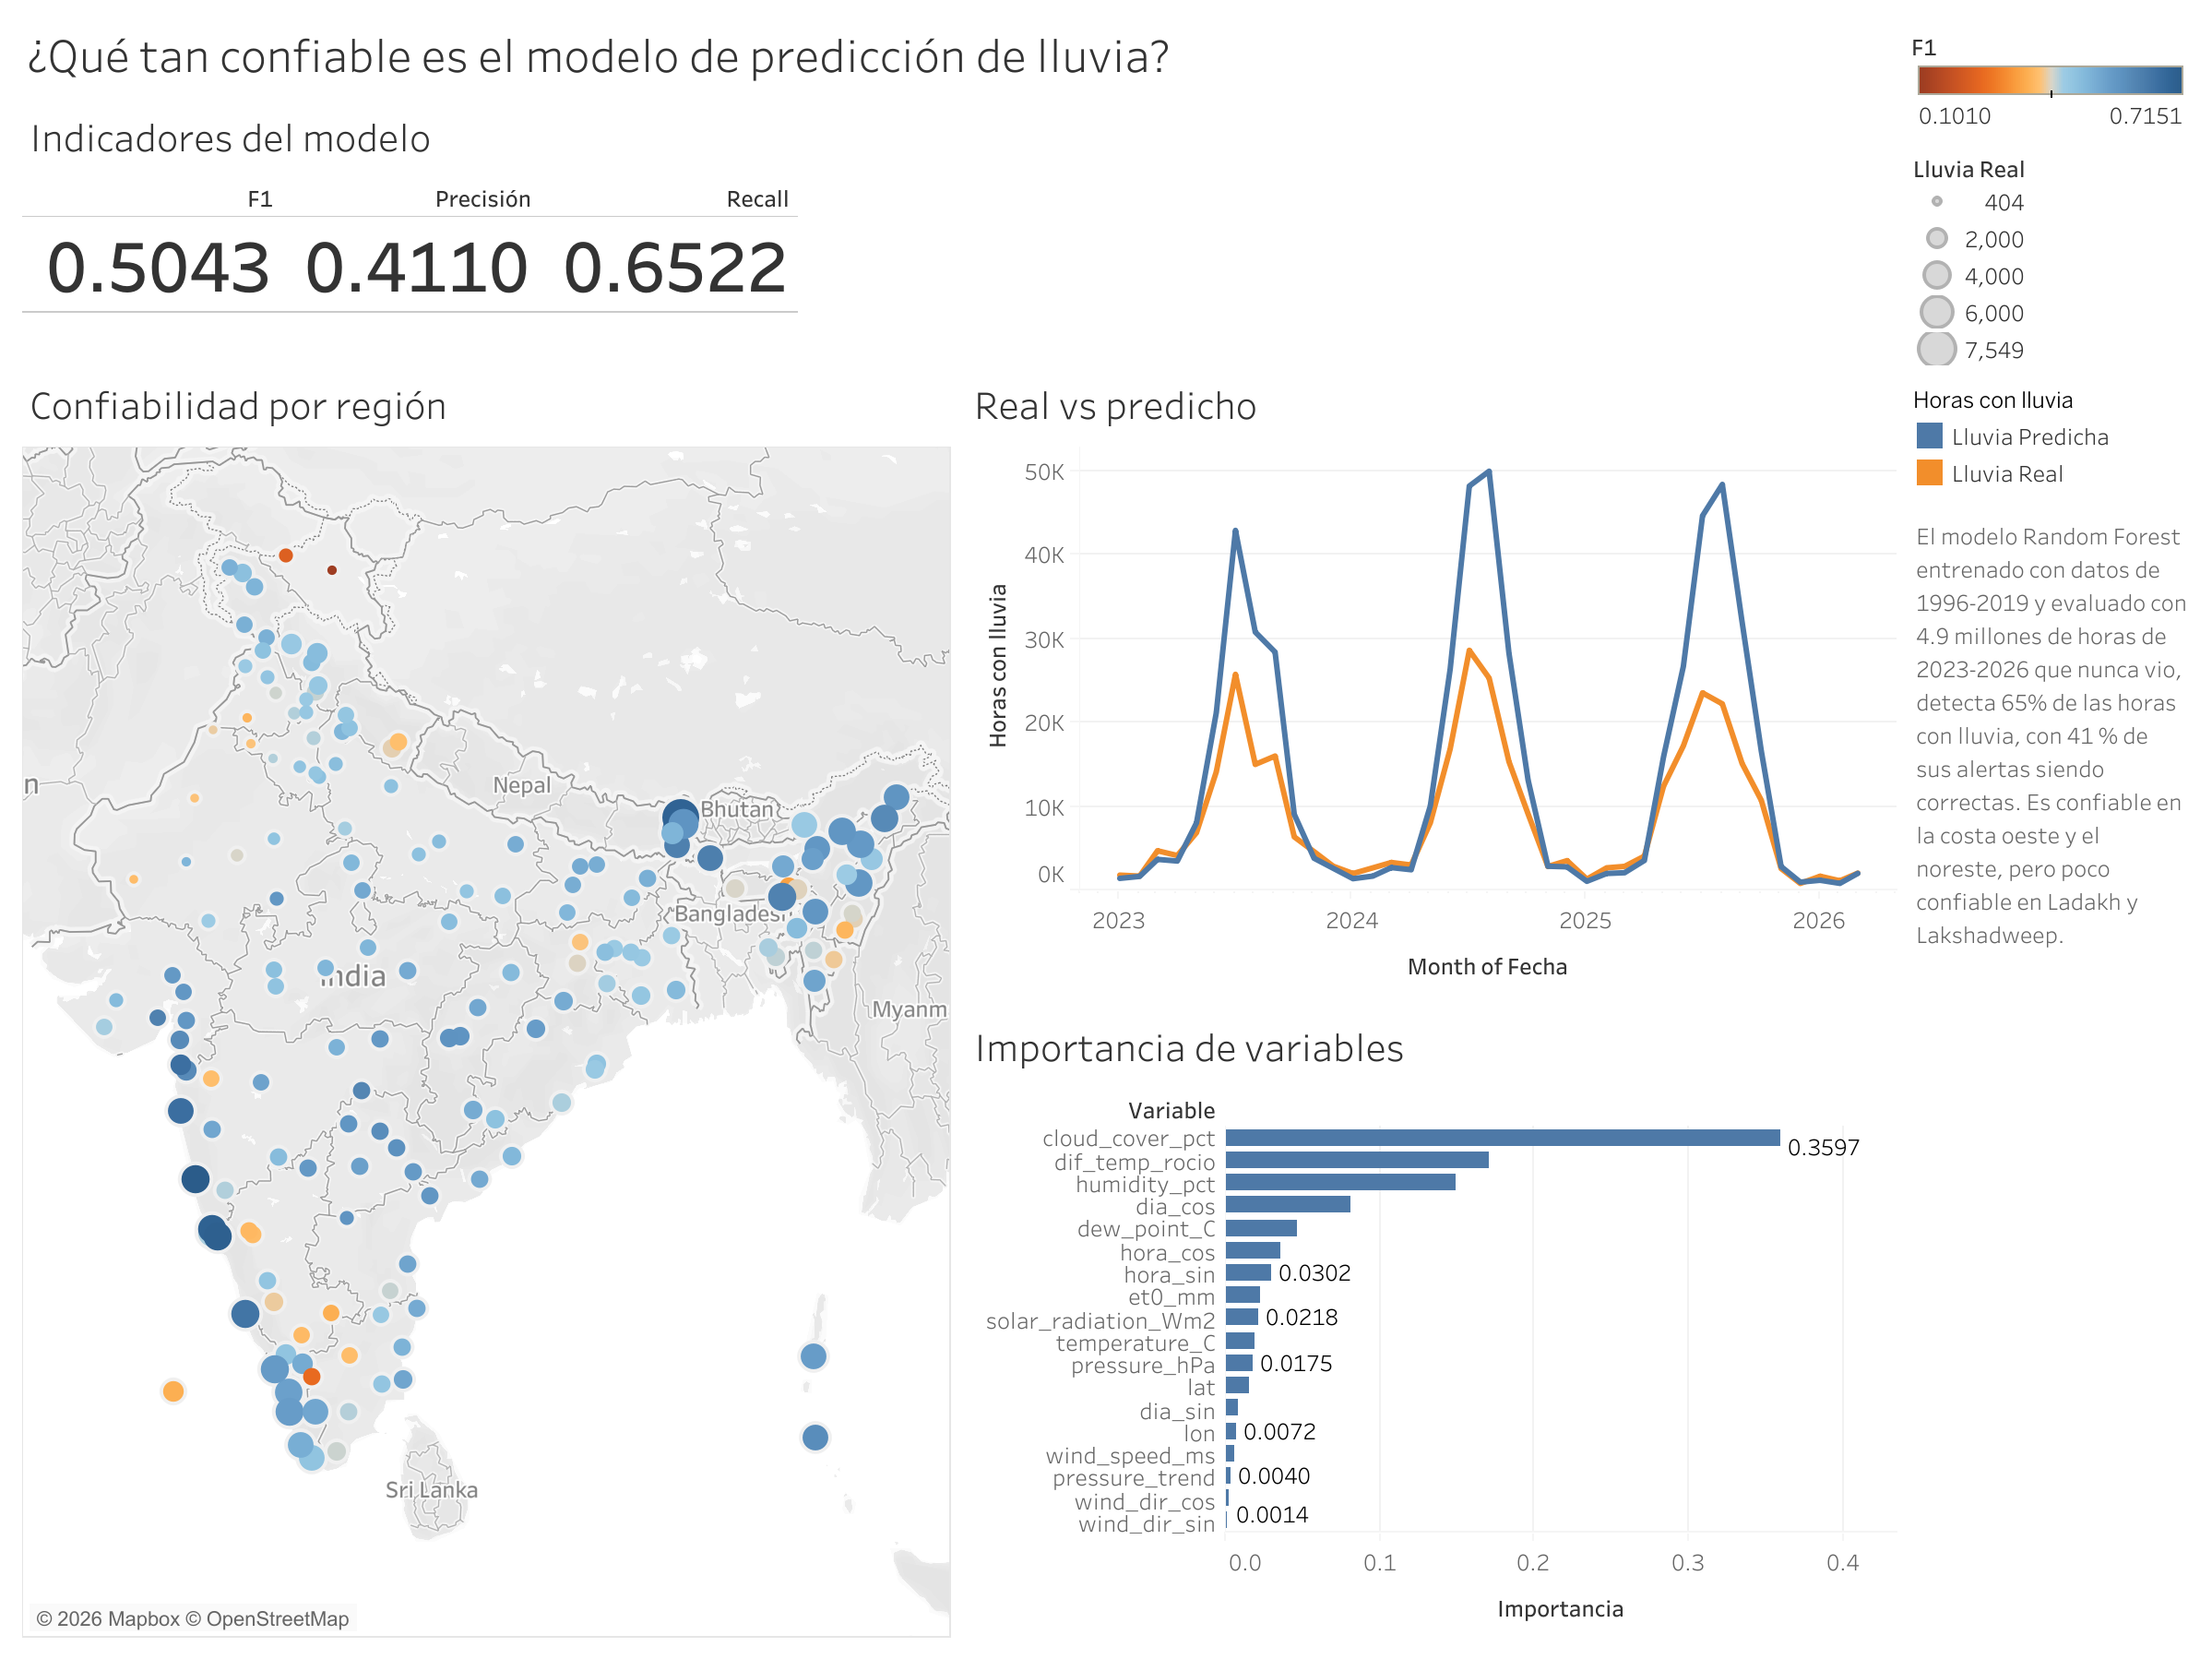

## 14. Conclusiones

El Random Forest superó a la regresión logística en validación con un AUC-PR de 0.55 vs 0.45, lo que indica que la relación entre las condiciones del aire y la lluvia no es lineal. En la prueba con 4.9 millones de horas de 2023 a marzo de 2026 que el modelo nunca vio, obtuvo AUC-ROC de 0.93, F1 de 0.50, recall de 0.65 y precisión de 0.41. Son básicamente las mismas métricas de validación, por lo que el modelo sí generaliza a años nuevos. Su accuracy de 0.91 es menor que la de un modelo que siempre predice no llueve (0.93), pero ese modelo no detecta ninguna lluvia, ya que con solo 8.8% de horas lluviosas, la accuracy no sirve para evaluar este problema.

Las variables más importantes fueron la nubosidad, la diferencia entre temperatura y punto de rocío (variable creada en la data preparation) y la humedad, que suman el 68% de la importancia. El modelo decide sobre todo por qué tan saturado está el aire, y después por la época del año y la hora del día. Por otro lado, sus falsas alarmas se concentran en el monzón, cuando hay muchas horas húmedas y nubladas en las que no llegan a caer 0.5mm. Es confiable en la costa oeste y el noreste con un F1 cercano a 0.6, y poco confiable en Ladakh con 0.18 y Lakshadweep con 0.35, cuyas condiciones están poco representadas en el entrenamiento.

Analizando los datos con tableau se observa que la lluvia se concentra de junio a septiembre, con un pico entre las 13 y las 17h. Tamil Nadu y Puducherry son la excepción, debido a que su temporada de lluvias es de octubre a diciembre. La precipitación media aumentó alrededor de 7.8mm por año entre 1996 y 2025 (p = 0.002), con mucha variación de un año a otro.

Por la parte del procesamiento de los datos, Spark procesó 46 millones de registros (7.2GB) en Colab con 2 núcleos. La conversión a Parquet redujo los datos 90%, y el proceso completo, de la descarga a la evaluación, tomó unos 40 minutos. Y finalmente, los siguientes pasos para el modelo serían agregar las condiciones de las horas previas para pronosticar la hora siguiente, y talvez usar umbrales distintos por temporada o región.

## 15. Referencias

- sandeepgupta09. (2026). Indian Weather Dataset 1996–2026 [Conjunto de datos]. Kaggle. https://www.kaggle.com/datasets/sandeepgupta09/indian-weather-dataset-1996-2026
- Open-Meteo. Historical Weather API. https://open-meteo.com/en/docs/historical-weather-api
- Apache Spark. MLlib: Main Guide (Classification and regression; ML Tuning: model selection and hyperparameter tuning). https://spark.apache.org/docs/latest/ml-guide.html
- Apache Spark. Parquet Files - Spark SQL Guide. https://spark.apache.org/docs/latest/sql-data-sources-parquet.html